# EDA — PAD-UFES-20
Distribución de clases, partición por paciente, fototipo Fitzpatrick y tamaños de imagen. Las figuras se guardan en `results/figures/`.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
import pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from src.data import load_pad, CLASSES
os.makedirs('results/figures', exist_ok=True)
df = load_pad('data/raw/pad').merge(pd.read_csv('data/splits/pad_split.csv')[['img_id', 'split']], on='img_id')
len(df), df['patient_id'].nunique(), df['lesion_id'].nunique()

(2298, 1373, 1641)

## Clases por partición

split,train,val,test,total,pct
diagnostic,,,,,
ACK,522,104,104,730,31.8
BCC,603,121,121,845,36.8
MEL,37,8,7,52,2.3
NEV,174,35,35,244,10.6
SCC,136,28,28,192,8.4
SEK,168,33,34,235,10.2


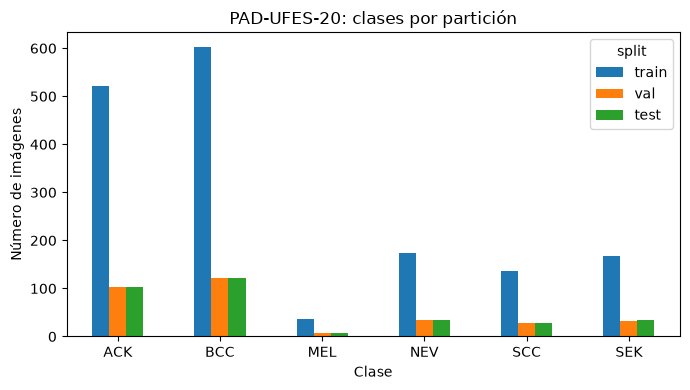

In [2]:
ct = pd.crosstab(df['diagnostic'], df['split'])[['train', 'val', 'test']].loc[CLASSES]
ax = ct.plot.bar(figsize=(7, 4), rot=0)
ax.set_xlabel('Clase'); ax.set_ylabel('Número de imágenes'); ax.set_title('PAD-UFES-20: clases por partición')
plt.tight_layout(); plt.savefig('results/figures/eda_classes.png', dpi=200)
ct.assign(total=ct.sum(axis=1), pct=(ct.sum(axis=1) / len(df) * 100).round(1))

## Imágenes por paciente
Varias imágenes por paciente: si la partición fuera por imagen habría fuga de datos.

In [3]:
per_patient = df.groupby('patient_id').size()
print(per_patient.describe())
print('pacientes con >1 imagen:', (per_patient > 1).sum())
df.groupby('split')['patient_id'].nunique()

count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
dtype: float64
pacientes con >1 imagen: 544


split
test     197
train    980
val      196
Name: patient_id, dtype: int64

## Fototipo Fitzpatrick (análisis de sesgo)

faltantes: 0.35


fitspatrick,1,2,3,4,5,6,NA,All
diagnostic,,,,,,,,
ACK,25,156,89,10,3,0,447,730
BCC,101,502,217,22,3,0,0,845
MEL,3,35,10,4,0,0,0,52
NEV,4,34,24,12,1,0,169,244
SCC,16,126,45,3,2,0,0,192
SEK,4,23,7,11,1,1,188,235
All,153,876,392,62,10,1,804,2298


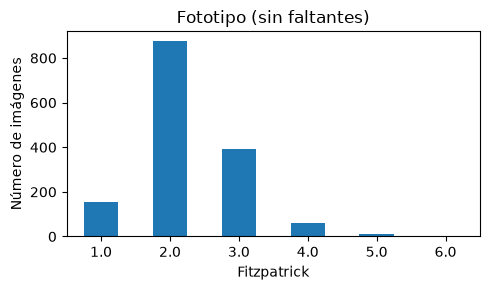

In [4]:
fitz = pd.crosstab(df['diagnostic'], df['fitspatrick'].fillna(0).astype(int).replace(0, 'NA'), margins=True)
print('faltantes:', df['fitspatrick'].isna().mean().round(3))
counts = df['fitspatrick'].value_counts().sort_index()
ax = counts.plot.bar(figsize=(5, 3), rot=0)
ax.set_xlabel('Fitzpatrick'); ax.set_ylabel('Número de imágenes'); ax.set_title('Fototipo (sin faltantes)')
plt.tight_layout(); plt.savefig('results/figures/eda_fitzpatrick.png', dpi=200)
fitz

## Tamaños de imagen (heterogeneidad de adquisición)

In [5]:
sizes = pd.DataFrame([Image.open(p).size for p in df['path']], columns=['w', 'h'])
print(sizes.describe().round(0))
sizes.value_counts().head(10)

            w       h
count  2298.0  2298.0
mean    934.0   934.0
std     535.0   535.0
min     147.0   147.0
25%     528.0   527.0
50%     780.0   780.0
75%    1219.0  1219.0
max    3474.0  3476.0


w     h   
750   750     75
640   640     40
1242  1242    17
1125  1125    10
2268  2268     6
534   534      6
433   433      6
542   542      6
751   751      5
502   502      5
Name: count, dtype: int64

## Ejemplos por clase

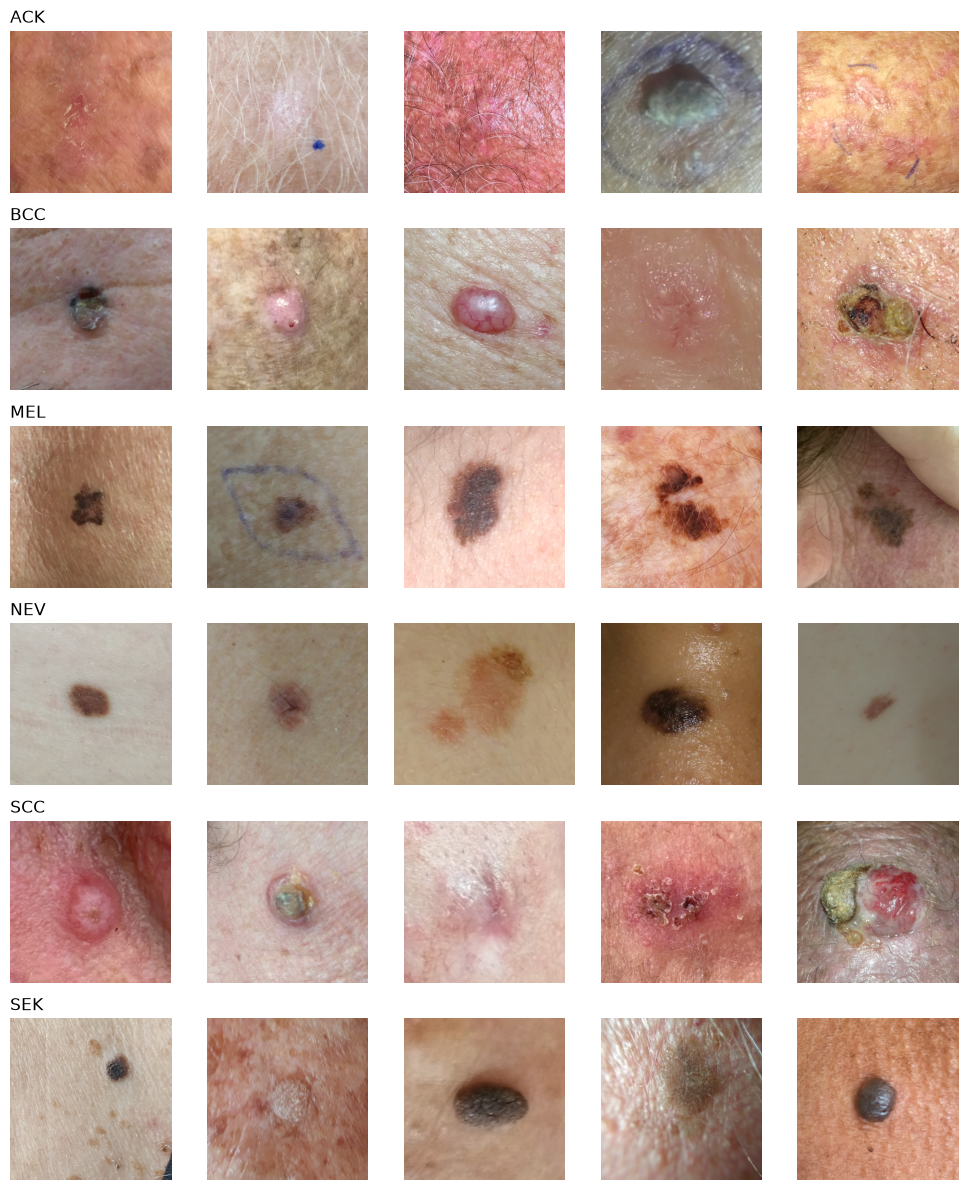

In [6]:
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(10, 12))
for r, c in enumerate(CLASSES):
    for ax, p in zip(axes[r], df[df['diagnostic'] == c].sample(5, random_state=0)['path']):
        ax.imshow(Image.open(p).convert('RGB')); ax.axis('off')
    axes[r, 0].set_title(c, loc='left')
plt.tight_layout(); plt.savefig('results/figures/eda_samples.png', dpi=120)